---
title: "Calculus of Variations"
short_title: "M5 Calculus of Variations"
numbering:
  heading_2: true
  equation: true
---

# Calculus of Variations

:::{tip} Where this sits in the plan
Math for **Lagrangian mechanics**. Builds on M3 (partial derivatives and Lagrange multipliers).

| Item | Boas | Arfken |
|---|---|---|
| Calculus of variations | 9 | 22 |
| Lagrange multipliers (integral constraints) | 4, 9 | 22 |

Chapter numbers are approximate, as in the workbook.
:::

Ordinary calculus finds the point where a function is stationary. The calculus of variations finds the **function** that makes an integral stationary. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Functionals

A **functional** takes a whole function and returns a number. The standard form is

$$
S[y] = \int_{x_1}^{x_2} f\big(y(x),\ y'(x),\ x\big)\,dx ,
$$ (eq-functional)

with the endpoint values $y(x_1)$ and $y(x_2)$ fixed. Three examples:

- **Length** of a curve $y(x)$: $f = \sqrt{1 + y'^2}$.
- **Travel time** of a bead sliding from rest down a wire $y(x)$ (with $y$ measured downward): $f = \sqrt{(1 + y'^2)/(2gy)}$.
- **Action** of a mechanical path $q(t)$: $f = \mathcal{L}(q, \dot q, t) = T - U$.

We want the $y(x)$ for which $S$ is **stationary**: small changes to $y$ leave $S$ unchanged to first order.

## The Euler–Lagrange Equation

Perturb the path: $y(x)\to y(x) + \alpha\,\eta(x)$, where $\eta$ is any smooth function that vanishes at both endpoints. Then $S$ becomes an ordinary function of $\alpha$, and stationarity means $dS/d\alpha = 0$ at $\alpha = 0$ for every $\eta$:

$$
\frac{dS}{d\alpha}\bigg|_0 = \int_{x_1}^{x_2}\left(\frac{\partial f}{\partial y}\eta + \frac{\partial f}{\partial y'}\eta'\right)dx .
$$

Integrate the second term by parts. The boundary term $\big[\eta\,\partial f/\partial y'\big]_{x_1}^{x_2}$ vanishes because $\eta$ does at the endpoints:

$$
\frac{dS}{d\alpha}\bigg|_0 = \int_{x_1}^{x_2}\eta(x)\left(\frac{\partial f}{\partial y} - \frac{d}{dx}\frac{\partial f}{\partial y'}\right)dx = 0 .
$$

Since $\eta$ is arbitrary, the bracket must vanish everywhere (otherwise choose $\eta$ concentrated where it is nonzero).

:::{prf:theorem} Euler–Lagrange equation
:label: thm-euler-lagrange

The path that makes {eq}`eq-functional` stationary satisfies

$$
\frac{\partial f}{\partial y} - \frac{d}{dx}\frac{\partial f}{\partial y'} = 0 .
$$ (eq-el)
:::

:::{warning} Partial versus total derivative
In {eq}`eq-el`, $\partial f/\partial y$ and $\partial f/\partial y'$ treat $y$ and $y'$ as independent variables. The $d/dx$ is a **total** derivative along the path, so it brings in $y'$ and $y''$ through the chain rule (see M3).
:::

::::{prf:example} Shortest path in the plane
:label: ex-straight-line

Show that the shortest curve between two points is a straight line.

:::{dropdown} Solution
With $f = \sqrt{1 + y'^2}$, $\partial f/\partial y = 0$, so {eq}`eq-el` says $\partial f/\partial y'$ is constant:

$$
\frac{y'}{\sqrt{1 + y'^2}} = C \quad\Longrightarrow\quad y' = \text{constant} .
$$

A constant slope is a straight line. Strictly, the argument shows the line is **stationary**; that it is a minimum is geometrically obvious here.
:::
::::

In [2]:
# sympy builds the Euler-Lagrange equation for you
from sympy.calculus.euler import euler_equations
x = sp.symbols("x")
y = sp.Function("y")(x)
for name, f in [(r"\text{length}", sp.sqrt(1 + y.diff(x)**2)), ("f = y'^2 + y^2", y.diff(x)**2 + y**2)]:
    eq = euler_equations(f, y, x)[0]
    display(Math(name + r":\quad " + sp.latex(sp.simplify(eq.lhs)) + " = 0"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## A First Integral: the Beltrami Identity

If $f$ does not depend explicitly on $x$, the Euler–Lagrange equation can be integrated once:

$$
f - y'\frac{\partial f}{\partial y'} = \text{constant} .
$$ (eq-beltrami)

To check it, differentiate the left side with respect to $x$ and use {eq}`eq-el`. Everything cancels. This turns a second-order equation into a first-order one. In mechanics the same identity, with $x\to t$, is **conservation of energy** for a Lagrangian with no explicit time dependence.

::::{prf:example} The fastest slide (brachistochrone)
:label: ex-brachistochrone

A bead starts from rest at the origin and slides without friction to a lower point. Which wire shape gets it there fastest?

:::{dropdown} Solution
With $y$ measured downward, the speed is $\sqrt{2gy}$, and the time is $\int\sqrt{(1 + y'^2)/(2gy)}\,dx$. Drop the constant $1/\sqrt{2g}$ and use {eq}`eq-beltrami` with $f = \sqrt{(1 + y'^2)/y}$:

$$
\sqrt{\frac{1 + y'^2}{y}} - \frac{y'^2}{\sqrt{y(1 + y'^2)}} = \frac{1}{\sqrt{y(1 + y'^2)}} = \text{const} \quad\Longrightarrow\quad y\left(1 + y'^2\right) = 2a .
$$

The substitution $y = a(1 - \cos\theta)$ solves this and gives $x = a(\theta - \sin\theta)$: a **cycloid**, the curve traced by a point on the rim of a rolling wheel. It dips steeply at first to build up speed early.
:::
::::

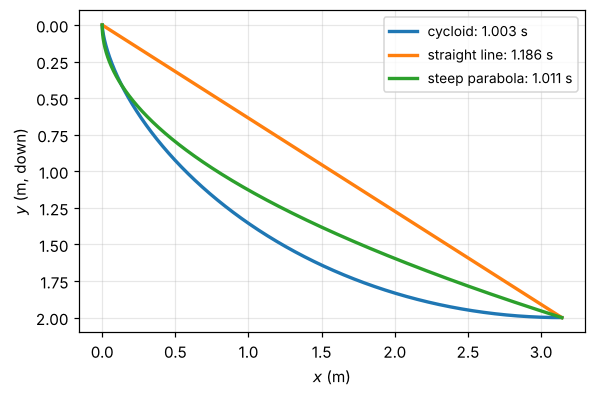

exact cycloid time pi*sqrt(a/g) = 1.003 s


In [3]:
#| label: fig-brachistochrone
#| caption: Three wires from (0, 0) to (π, 2) (y measured downward, a = 1). The cycloid is fastest even though it is longer than the straight line: it drops steeply enough to gain speed early, but not so steeply that it wastes distance like the parabola.
gval = 9.81
a = 1.0
X2, Y2 = np.pi * a, 2 * a                      # the cycloid's lowest point, at theta = pi

def time_along(xs, ys):
    # T = ∫ ds / sqrt(2 g y), with a small offset to avoid the 1/sqrt(0) start
    ds = np.hypot(np.diff(xs), np.diff(ys))
    ymid = 0.5 * (ys[1:] + ys[:-1])
    return np.sum(ds / np.sqrt(2 * gval * ymid))

th = np.linspace(0, np.pi, 20001)
paths = {
    "cycloid": (a * (th - np.sin(th)), a * (1 - np.cos(th))),
    "straight line": (np.linspace(0, X2, 20001), np.linspace(0, Y2, 20001)),
    "steep parabola": (X2 * np.linspace(0, 1, 20001)**2, Y2 * np.linspace(0, 1, 20001)),
}
fig, ax = plt.subplots(figsize=(7, 3.8))
for name, (xs, ys) in paths.items():
    ax.plot(xs, ys, lw=2.2, label=f"{name}: {time_along(xs, ys):.3f} s")
ax.invert_yaxis(); ax.set_aspect("equal"); ax.set_xlabel("$x$ (m)"); ax.set_ylabel("$y$ (m, down)")
ax.legend(fontsize=9); plt.show()
print("exact cycloid time pi*sqrt(a/g) =", round(np.pi * np.sqrt(a / gval), 3), "s")

## Several Functions

If $f$ depends on several functions $y_1(x), \dots, y_n(x)$ and their derivatives, perturb each one independently. The result is one Euler–Lagrange equation per function:

$$
\frac{\partial f}{\partial y_i} - \frac{d}{dx}\frac{\partial f}{\partial y_i'} = 0, \qquad i = 1, \dots, n .
$$

This is the form used in mechanics, with one equation per generalized coordinate. Because the derivation never assumed anything about which variables are used, the equations take the same form in **any** coordinates. That coordinate freedom is the main practical advantage of Lagrangian mechanics.

## Constraints

### Integral constraints

To make $S[y]$ stationary while holding another functional fixed, $K[y] = \int g(y, y', x)\,dx = \text{const}$, introduce a multiplier as in M3 and apply Euler–Lagrange to $f + \lambda g$:

$$
\frac{\partial(f + \lambda g)}{\partial y} - \frac{d}{dx}\frac{\partial(f + \lambda g)}{\partial y'} = 0 .
$$

The classic case is the **hanging chain**: minimize potential energy $\int\rho g\,y\,ds$ at fixed length $\int ds$. The answer is a **catenary**, $y = a\cosh\big((x - x_0)/a\big) + c$.

### Pointwise constraints

If the functions must satisfy a relation at every point, $g(y_1, y_2, x) = 0$, the multiplier becomes a function $\lambda(x)$. In mechanics such a relation is a **holonomic constraint** (a bead on a wire, a pendulum rod), and $\lambda(t)$ turns out to be the constraint force. The Lagrangian notes use this to find the tension in a pendulum.

### Exercises

1. Find the Euler–Lagrange equation for $f = y'^2 + y^2$ and solve it with $y(0) = 0$, $y(1) = 1$.
2. Find the shortest path (geodesic) on the surface of a cylinder of radius $R$. Use coordinates $(\phi, z)$ and $ds^2 = R^2d\phi^2 + dz^2$.
3. Use {eq}`eq-beltrami` to find the curve $y(x) > 0$ that, rotated about the $x$-axis, gives the surface of least area: $f = y\sqrt{1 + y'^2}$.

:::{dropdown} Hints
1. The equation is linear with constant coefficients.
2. Write $z(\phi)$ and $f = \sqrt{R^2 + z'^2}$. Since $f$ has no explicit $z$, $\partial f/\partial z'$ is constant.
3. The identity gives $y/\sqrt{1 + y'^2} = a$. Separate variables.
:::

:::{dropdown} Answers
1. $y'' = y$, so $y = \sinh x/\sinh 1$.
2. $z' = $ constant, so $z = c\phi + d$: a helix, which unrolls to a straight line on the flattened cylinder.
3. $y = a\cosh\big((x - x_0)/a\big)$, a catenary. The surface is a catenoid, the shape of a soap film stretched between two rings.
:::

## Summary

- A functional $S[y] = \int f(y, y', x)\,dx$ is stationary when $y$ satisfies the Euler–Lagrange equation {eq}`eq-el`.
- If $f$ has no explicit $x$, the Beltrami identity gives a first integral, which becomes energy conservation in mechanics.
- With several functions there is one equation per function, in the same form in any coordinates.
- Integral constraints add a constant multiplier; pointwise constraints add a multiplier function, which becomes a constraint force in mechanics.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.